# Estimator プリミティブでのエラー緩和オプションの組み合わせ

*使用量の目安: Heron r2 プロセッサで 7 分（注意: これはあくまで目安です。実際の実行時間は異なる場合があります。）*

## 学習成果

* 動的デカップリング、測定エラー緩和、ゲート・ツワーリング、ゼロノイズ外挿をハードウェア上で個別に適用する方法
* それぞれの手法がハードウェアのノイズをどの程度緩和できるかの比較

## 前提知識

* こちらの [ガイド](/docs/guides/error-mitigation-and-suppression-techniques) で説明されている、動的デカップリング、測定エラー緩和、ゲート・ツワーリング、ゼロノイズ外挿の基礎

## 背景

このチュートリアルでは、IBM Quantum Estimator プリミティブで利用できるエラー抑制およびエラー緩和のオプションについて学びます。次の各手法を個別に適用する方法を示します。

* 動的デカップリング
* 測定エラー緩和
* ゲート・ツワーリング
* ゼロノイズ外挿（ZNE）

なお、これらの手法を個別に適用する代わりに、[レジリエンス・レベル](/docs/guides/estimator-noise-management) を使って適用することもできます。`resilience_level` には 0、1、2 の値を指定できます。

* 0 : 緩和は一切適用されません。
* 1 : 測定エラー緩和が適用されます。
* 2 : ゲート・ツワーリング、測定エラー緩和、ZNE が適用されます。

このチュートリアルでは、回路と観測量を構成し、さまざまなエラー緩和設定の組み合わせで Estimator プリミティブにジョブを投入します。その後、結果をプロットして各設定の効果を確認します。可視化しやすいように、チュートリアルの大部分では 10 量子ビットの回路を使い、最後にワークフローを 50 量子ビットへ拡張します。

## 要件

このチュートリアルを始める前に、次のものがインストールされていることを確認してください。

* Qiskit SDK v2.1 以降（[可視化](/docs/api/qiskit/visualization) サポート付き）
* Qiskit Runtime v0.40 以降（`pip install qiskit-ibm-runtime`）

## セットアップ

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from qiskit.circuit.library import efficient_su2, unitary_overlap
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime import Batch, EstimatorV2 as Estimator

## 小規模なシミュレーターでの例

Runtime のエラー緩和はシミュレーターではサポートされていないため、このステップは省略します。

## ハードウェアでの例

### ステップ 1: 古典的な入力を量子問題へマッピングする

このチュートリアルでは、古典的な問題がすでに量子問題へマッピングされていることを前提とします。まず、測定する回路と観測量を構成します。ここで使う手法はさまざまな種類の回路に適用できますが、簡単のため、Qiskit の回路ライブラリーに含まれる [`efficient_su2`](/docs/api/qiskit/qiskit.circuit.library.efficient_su2) 回路を使います。

`efficient_su2` は、量子ビットの接続性が限られた量子ハードウェア上で効率よく実行できるよう設計されたパラメーター化量子回路であり、最適化や化学といった応用分野の問題を解くのに十分な表現力も備えています。この回路は、パラメーター化された 1 量子ビット・ゲートの層と、固定パターンの 2 量子ビット・ゲートからなる層を、指定した繰り返し回数だけ交互に並べて構成されます。2 量子ビット・ゲートのパターンはユーザーが指定できます。ここでは組み込みの `pairwise` パターンを使います。このパターンは 2 量子ビット・ゲートをできるだけ密に詰めることで回路の深さを最小化し、線形な量子ビット接続性だけで実行できます。

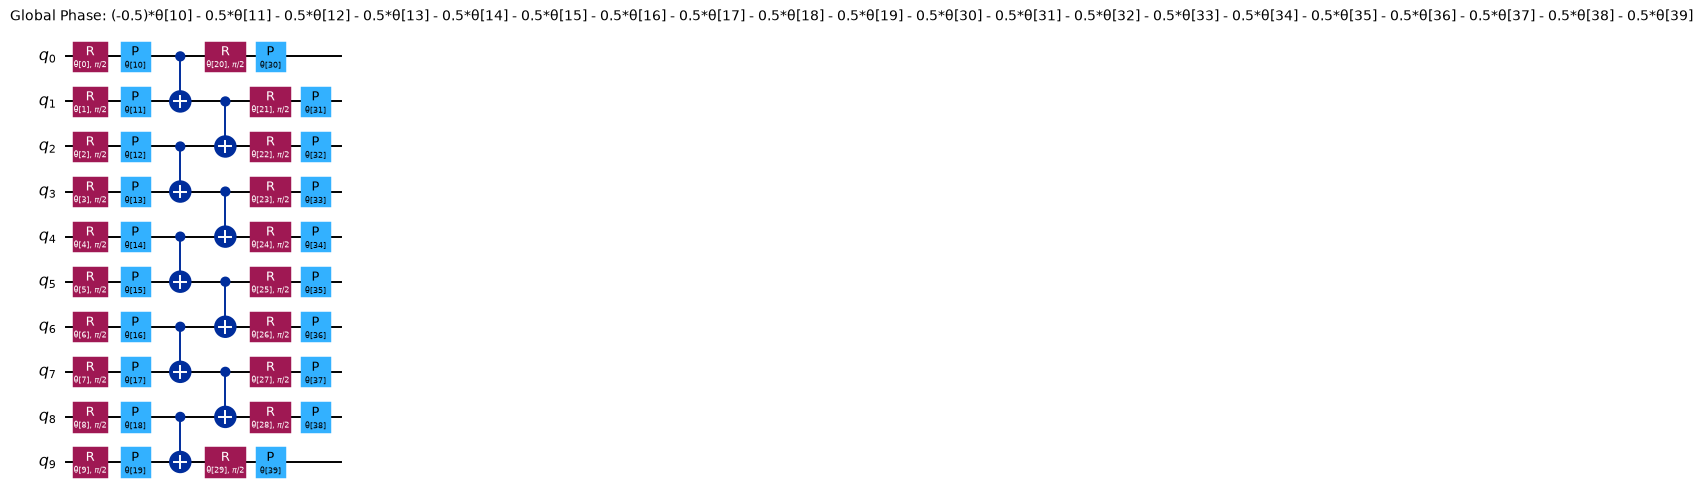

In [2]:
n_qubits = 10
reps = 1

circuit = efficient_su2(n_qubits, entanglement="pairwise", reps=reps)

circuit.decompose().draw("mpl", scale=0.7)

観測量としては、最後の量子ビットに作用するパウリ $Z$ 演算子 $Z I \cdots I$ を使います。
最後の量子ビットがこの文字列の最初の要素に対応しているのは、Qiskit がリトルエンディアン表記を採用しているためです。

In [3]:
# 最後の量子ビット（インデックス -1）に係数 1.0 の Z を作用させる
observable = SparsePauliOp.from_sparse_list(
    [("Z", [-1], 1.0)], num_qubits=n_qubits
)

この時点で回路を実行して観測量を測定することもできますが、量子デバイスの出力を正しい答え、つまりエラーなしで回路を実行した場合の観測量の理論値と比較したいところです。小さな量子回路であれば古典コンピューターで回路をシミュレートしてこの値を計算できますが、より大規模なユーティリティー・スケールの回路ではそれができません。この問題は「ミラー回路」手法（「compute-uncompute」とも呼ばれます）で回避できます。この手法は量子デバイスの性能のベンチマークに役立ちます。

#### ミラー回路

ミラー回路の手法では、元の回路に、その逆回路を連結します。逆回路は、回路の各ゲートを逆順に並べてそれぞれの逆演算をとることで作られます。得られる回路は恒等演算子を実装するため、簡単にシミュレートできます。ミラー回路には元の回路の構造が保たれているので、ミラー回路を実行すれば、量子デバイスが元の回路に対してどの程度の性能を発揮するかの目安が得られます。

次のコードセルでは、回路にランダムなパラメーターを割り当ててから、[`unitary_overlap`](/docs/api/qiskit/qiskit.circuit.library.unitary_overlap) クラスを使ってミラー回路を構成します。回路をミラーリングする前に [バリア](/docs/api/qiskit/circuit#qiskit.circuit.Barrier) 命令を追加しておきます。これにより、トランスパイラーがバリアの両側にある回路の 2 つの部分をまとめてしまい、ゲートがまったくないトランスパイル済み回路になってしまうのを防ぎます。

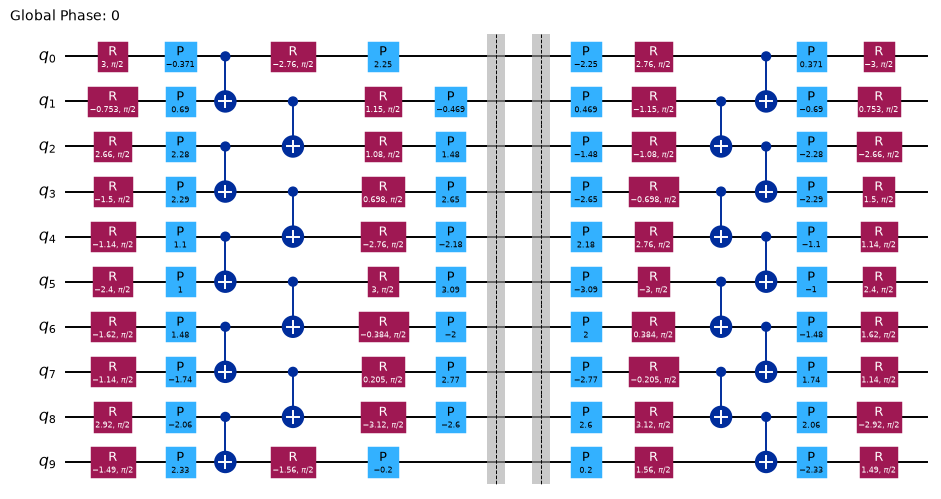

In [4]:
# ランダムなパラメーターを生成する
rng = np.random.default_rng(1234)
params = rng.uniform(-np.pi, np.pi, size=circuit.num_parameters)

# パラメーターを回路に割り当てる
assigned_circuit = circuit.assign_parameters(params)

# ミラーリングした演算子が回路最適化で打ち消されないようにバリアを追加する
assigned_circuit.barrier()

# ミラー回路を構成する
mirror_circuit = unitary_overlap(assigned_circuit, assigned_circuit)

mirror_circuit.decompose().draw("mpl", scale=0.7)

### ステップ 2: 量子ハードウェアでの実行に向けて問題を最適化する

ハードウェアで実行する前に、回路を最適化する必要があります。このプロセスには、次のステップが含まれます。

* 回路の仮想量子ビットをハードウェアの物理量子ビットに対応付ける量子ビット・レイアウトを選ぶ。
* 接続されていない量子ビット間の相互作用をルーティングするために、必要に応じて SWAP ゲートを挿入する。
* 回路内のゲートを、ハードウェアで直接実行できる [命令セット・アーキテクチャー（ISA）](/docs/guides/transpile#instruction-set-architecture) の命令に変換する。
* 回路の深さとゲート数を最小化するために回路最適化を行う。

Qiskit に組み込まれているトランスパイラーは、これらのステップをすべて実行できます。この例ではハードウェア効率の良い回路を使っているため、トランスパイラーは相互作用のルーティングのために SWAP ゲートを挿入する必要のない量子ビット・レイアウトを選べるはずです。

回路を最適化する前に、使用するハードウェア・デバイスを選ぶ必要があります。次のコードセルでは、127 量子ビット以上を持つデバイスのうち、最も混雑していないものを要求します。

In [5]:
service = QiskitRuntimeService()
backend = service.least_busy(
    operational=True, simulator=False, min_num_qubits=127
)

In [6]:
print(backend)

<IBMBackend('ibm_kingston')>


パス・マネージャーを作成し、それを回路に対して実行することで、選んだバックエンド向けに回路をトランスパイルできます。パス・マネージャーを作成する簡単な方法は、[`generate_preset_pass_manager`](/docs/api/qiskit/qiskit.transpiler.generate_preset_pass_manager) 関数を使うことです。パス・マネージャーを使ったトランスパイルの詳しい説明は、[パス・マネージャーを使ったトランスパイル](/docs/guides/transpile-with-pass-managers) を参照してください。

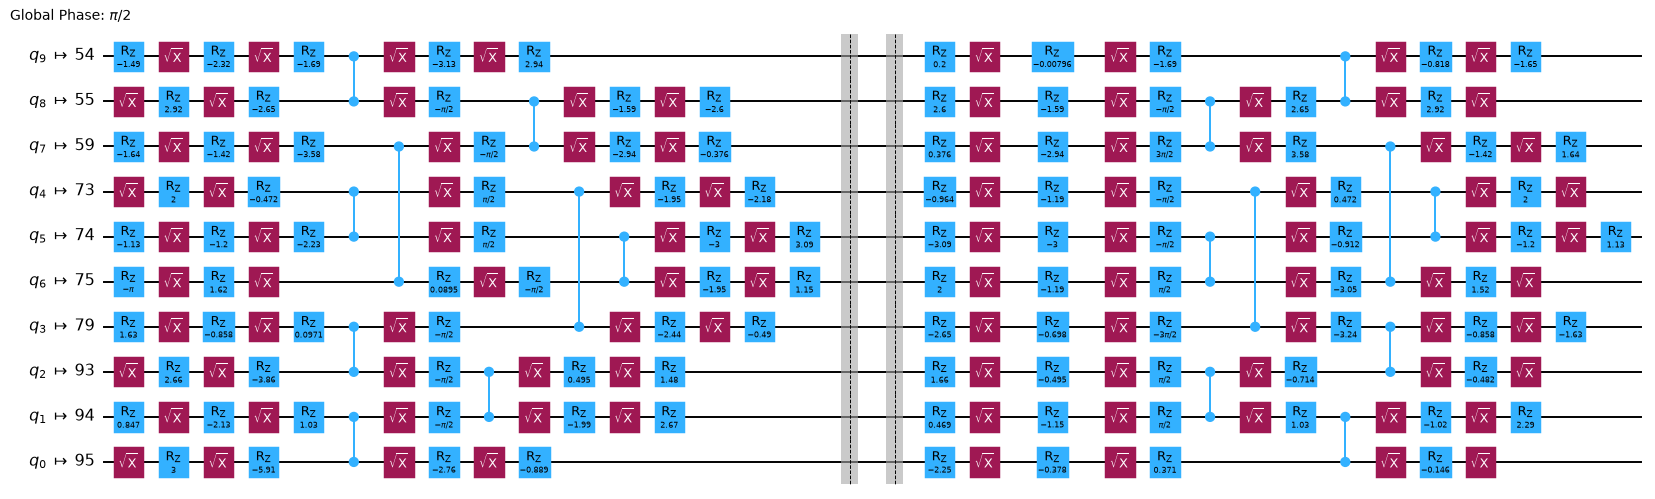

In [7]:
pass_manager = generate_preset_pass_manager(
    optimization_level=3, backend=backend, seed_transpiler=1234
)
isa_circuit = pass_manager.run(mirror_circuit)

isa_circuit.draw("mpl", idle_wires=False, scale=0.7, fold=-1)

トランスパイル後の回路には ISA 命令だけが含まれています。すべてのゲートは $\sqrt{X}$ ゲート、$R_z$ 回転、[CZ ゲート](/docs/api/qiskit/qiskit.circuit.library.CZGate) に分解されています。

トランスパイルのプロセスでは、回路の仮想量子ビットがハードウェアの物理量子ビットに対応付けられています。量子ビット・レイアウトの情報は、トランスパイル済み回路の `layout` 属性に格納されています。観測量も仮想量子ビットに基づいて定義されているため、このレイアウトを観測量にも適用する必要があります。これは `SparsePauliOp` の [`apply_layout`](/docs/api/qiskit/qiskit.quantum_info.SparsePauliOp#apply_layout) メソッドで行えます。

In [8]:
isa_observable = observable.apply_layout(isa_circuit.layout)

print("元の観測量:")
print(observable)
print()
print("レイアウトを適用した観測量:")
print(isa_observable)

元の観測量:
SparsePauliOp(['ZIIIIIIIII'],
              coeffs=[1.+0.j])

レイアウトを適用した観測量:
SparsePauliOp(['IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII'],
              coeffs=[1.+0.j])


### ステップ 3: Qiskit プリミティブを使って実行する

これで、Estimator プリミティブを使って回路を実行する準備が整いました。

ここでは 5 つの個別のジョブを投入します。最初はエラー抑制やエラー緩和を一切行わず、その後 IBM Quantum Compute Service で利用できるさまざまなエラー抑制・緩和のオプションを順に有効にしていきます。オプションについては、次のページを参照してください。

* [すべてのオプションの概要](/docs/api/qiskit-ibm-runtime/options)
* [動的デカップリング](/docs/api/qiskit-ibm-runtime/options-models-dynamical-decoupling-options)
* [レジリエンス（測定エラー緩和とゼロノイズ外挿（ZNE）を含む）](/docs/api/qiskit-ibm-runtime/options-models-resilience-options)
* [ツワーリング](/docs/api/qiskit-ibm-runtime/options-models-twirling-options)

これらのジョブは互いに独立して実行できるため、[バッチ・モード](/docs/guides/run-jobs-batch) を使うことで、Quantum Compute がジョブの実行タイミングを最適化できるようになります。

In [9]:
pub = (isa_circuit, isa_observable)

jobs = []

with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.environment.job_tags = [
        "TUT_CEM_SS"
    ]  # この小規模ジョブ用のタグを追加する
    # ショット数を設定する
    estimator.options.default_shots = 100_000
    # Runtime によるコンパイルとエラー緩和を無効にする
    estimator.options.resilience_level = 0

    # エラー緩和なしでジョブを実行する
    job0 = estimator.run([pub])
    jobs.append(job0)

    # 動的デカップリング（DD）を追加する
    estimator.options.dynamical_decoupling.enable = True
    estimator.options.dynamical_decoupling.sequence_type = "XpXm"
    job1 = estimator.run([pub])
    jobs.append(job1)

    # 読み出しエラー緩和を追加する（DD + TREX）
    estimator.options.resilience.measure_mitigation = True
    job2 = estimator.run([pub])
    jobs.append(job2)

    # ゲート・ツワーリングを追加する（DD + TREX + ゲート・ツワーリング）
    estimator.options.twirling.enable_gates = True
    estimator.options.twirling.num_randomizations = "auto"
    job3 = estimator.run([pub])
    jobs.append(job3)

    # ゼロノイズ外挿を追加する（DD + TREX + ゲート・ツワーリング + ZNE）
    estimator.options.resilience.zne_mitigation = True
    estimator.options.resilience.zne.noise_factors = (1, 3, 5)
    estimator.options.resilience.zne.extrapolator = ("exponential", "linear")
    job4 = estimator.run([pub])
    jobs.append(job4)

### ステップ 4: 後処理を行い、目的の古典形式で結果を返す

最後に、データを分析します。ここでは、ジョブの結果を取得し、そこから測定された期待値を取り出して、1 標準偏差のエラーバー付きでプロットします。

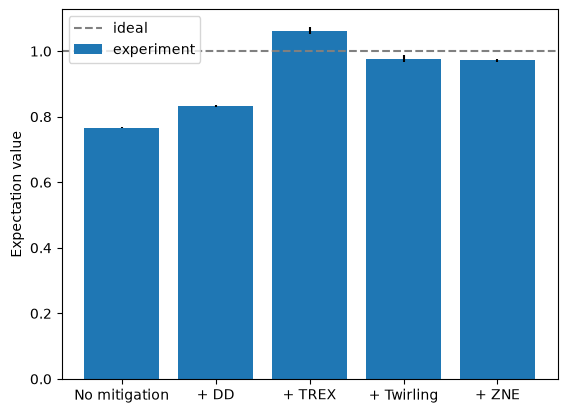

In [10]:
# ジョブの結果を取得する
results = [job.result() for job in jobs]

# PUB の結果を取り出す（各ジョブの結果には PUB の結果が 1 つだけ含まれる）
pub_results = [result[0] for result in results]

# 期待値と標準誤差を取り出す
expectation_vals = np.array(
    [float(pub_result.data.evs) for pub_result in pub_results]
)
standard_errors = np.array(
    [float(pub_result.data.stds) for pub_result in pub_results]
)

# 期待値をプロットする
fig, ax = plt.subplots()
labels = ["No mitigation", "+ DD", "+ TREX", "+ Twirling", "+ ZNE"]
ax.bar(
    range(len(labels)),
    expectation_vals,
    yerr=standard_errors,
    label="experiment",
)
ax.axhline(y=1.0, color="gray", linestyle="--", label="ideal")
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels)
ax.set_ylabel("Expectation value")
ax.legend(loc="upper left")

plt.show()

この小規模な例では、ほとんどのエラー緩和手法の効果を確認するのは困難ですが、ゼロノイズ外挿では目に見える改善が得られています。ただし、ZNE の結果はエラーバーも大きくなっていることから分かるように、この改善にはコストが伴う点に注意してください。

## 大規模なハードウェアでの例

実験を開発する際は、可視化やシミュレーションを容易にするために小さな回路から始めると便利です。10 量子ビットの回路でワークフローを開発・検証できたので、これを 50 量子ビットへ拡張します。次のコードセルでは、このチュートリアルのすべてのステップを繰り返し、今度は 50 量子ビットの回路に適用します。

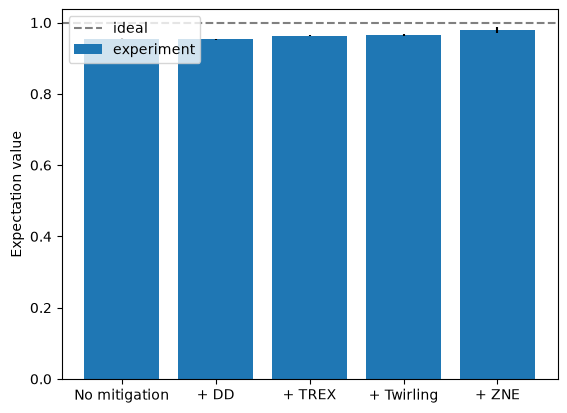

In [11]:
n_qubits = 50
reps = 1

# 回路と観測量を構成する
circuit = efficient_su2(n_qubits, entanglement="pairwise", reps=reps)
observable = SparsePauliOp.from_sparse_list(
    [("Z", [-1], 1.0)], num_qubits=n_qubits
)

# パラメーターを回路に割り当てる
params = rng.uniform(-np.pi, np.pi, size=circuit.num_parameters)
assigned_circuit = circuit.assign_parameters(params)
assigned_circuit.barrier()

# ミラー回路を構成する
mirror_circuit = unitary_overlap(assigned_circuit, assigned_circuit)

# 回路と観測量をトランスパイルする
isa_circuit = pass_manager.run(mirror_circuit)
isa_observable = observable.apply_layout(isa_circuit.layout)

# ジョブを実行する
pub = (isa_circuit, isa_observable)

jobs = []

with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.environment.job_tags = [
        "TUT_CEM_LS"
    ]  # この大規模ジョブ用のタグを追加する
    # ショット数を設定する
    estimator.options.default_shots = 100_000
    # Runtime によるコンパイルとエラー緩和を無効にする
    estimator.options.resilience_level = 0

    # エラー緩和なしでジョブを実行する
    job0 = estimator.run([pub])
    jobs.append(job0)

    # 動的デカップリング（DD）を追加する
    estimator.options.dynamical_decoupling.enable = True
    estimator.options.dynamical_decoupling.sequence_type = "XpXm"
    job1 = estimator.run([pub])
    jobs.append(job1)

    # 読み出しエラー緩和を追加する（DD + TREX）
    estimator.options.resilience.measure_mitigation = True
    job2 = estimator.run([pub])
    jobs.append(job2)

    # ゲート・ツワーリングを追加する（DD + TREX + ゲート・ツワーリング）
    estimator.options.twirling.enable_gates = True
    estimator.options.twirling.num_randomizations = "auto"
    job3 = estimator.run([pub])
    jobs.append(job3)

    # ゼロノイズ外挿を追加する（DD + TREX + ゲート・ツワーリング + ZNE）
    estimator.options.resilience.zne_mitigation = True
    estimator.options.resilience.zne.noise_factors = (1, 3, 5)
    estimator.options.resilience.zne.extrapolator = ("exponential", "linear")
    job4 = estimator.run([pub])
    jobs.append(job4)

# ジョブの結果を取得する
results = [job.result() for job in jobs]

# PUB の結果を取り出す（各ジョブの結果には PUB の結果が 1 つだけ含まれる）
pub_results = [result[0] for result in results]

# 期待値と標準誤差を取り出す
expectation_vals = np.array(
    [float(pub_result.data.evs) for pub_result in pub_results]
)
standard_errors = np.array(
    [float(pub_result.data.stds) for pub_result in pub_results]
)

# 期待値をプロットする
fig, ax = plt.subplots()
labels = ["No mitigation", "+ DD", "+ TREX", "+ Twirling", "+ ZNE"]
ax.bar(
    range(len(labels)),
    expectation_vals,
    yerr=standard_errors,
    label="experiment",
)
ax.axhline(y=1.0, color="gray", linestyle="--", label="ideal")
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels)
ax.set_ylabel("Expectation value")
ax.legend(loc="upper left")

plt.show()

50 量子ビットの結果を先ほどの 10 量子ビットの結果と比較すると、次のことに気付くかもしれません（結果は実行ごとに異なる場合があります）。

* すべての実験で結果が理想値に近づき、エラーバーもすべて小さくなっている。
* 動的デカップリングを追加すると、緩和なしの場合と比べて性能が悪化している可能性がある。これは回路が非常に密であることを考えると驚くことではありません。動的デカップリングが主に役立つのは、量子ビットにゲートが適用されずにアイドル状態となる大きな空き時間が回路内にある場合です。このような空き時間がない場合、動的デカップリングは効果がなく、動的デカップリングのパルス自体のエラーによって、かえって性能が悪化することもあります。10 量子ビットの回路では、この効果を観察するには小さすぎたのかもしれません。
* ゼロノイズ外挿を使うと、結果は理想値に非常に近くなる。これは ZNE の威力を示しています。

## 次のステップ

<Admonition type="tip" title="おすすめ">
  この内容に興味を持たれた方は、このチュートリアルでは取り上げなかった、その他のエラー緩和およびエラー抑制の手法に関する次の資料もご覧ください。

  * [確率的エラー・キャンセレーション（PEC）](/docs/guides/error-mitigation-and-suppression-techniques#probabilistic-error-cancellation-pec)
  * [行列フリー測定緩和（M3）](https://qiskit.github.io/qiskit-addon-mthree/)（[M3 を使った Sampler プリミティブの読み出しエラー緩和](/docs/tutorials/readout-error-mitigation-sampler/) のチュートリアルも参照してください）
  * [Shaded lightcones](https://qiskit.github.io/qiskit-addon-slc/)
  * [Propagated Noise Absorption（PNA）](https://qiskit.github.io/qiskit-addon-pna/)
</Admonition>

© IBM Corp., 2017-2026